<a href="https://colab.research.google.com/github/zhannaa0/kazakh-hybrid-nlp/blob/main/notebooks/01_data_preparation_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. Подготовка данных и EDA

Ноутбук закрывает три задачи этапа 1:

| № | Задача | Результат |
|---|---|---|
| 1 | Сбор и подготовка данных: получение KazNERD и UD Kazakh Treebank | Подготовленный датасет, описание структуры данных |
| 2 | Первичная очистка, единый формат, разбиения, фиксация версий | Визуализация данных до и после предобработки |
| 3 | Исследовательский анализ: выбросы, пропуски, классы, длины, редкие слова, дисбаланс | Аналитический отчёт с графиками |

Весь код лежит в `src/data/`; ноутбук только вызывает функции и показывает результат.
Рисунки сохраняются на Drive в `thesis/outputs/figures/` (PNG, 300 dpi — для диссертации).

## 0. Настройка окружения

In [1]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount('/content/drive')
    token = userdata.get('GH_TOKEN')
    !git clone -q https://{token}@github.com/zhannaa0/kazakh-hybrid-nlp.git /content/project 2>/dev/null || git -C /content/project pull -q
    %cd /content/project
    !pip install -q -r requirements.txt
    PROJECT = Path('/content/project')
    THESIS = Path('/content/drive/MyDrive/thesis')
else:                                   # запуск на своём компьютере
    PROJECT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
    THESIS = Path(os.environ.get('THESIS_DIR', PROJECT.parent / 'thesis'))

sys.path.insert(0, str(PROJECT))
RAW  = THESIS / 'data'                  # исходные файлы: kaznerd/, ud-ktb/
PROC = THESIS / 'data' / 'processed'    # результат подготовки
FIG  = THESIS / 'outputs' / 'figures'   # рисунки для диссертации
print(RAW, PROC, FIG, sep='\n')

Mounted at /content/drive
/content/project
/content/drive/MyDrive/thesis/data
/content/drive/MyDrive/thesis/data/processed
/content/drive/MyDrive/thesis/outputs/figures


In [2]:
import json
import pandas as pd
from IPython.display import display

from src.data import eda, plots
from src.data.prepare import load_raw, load_processed, prepare, read_jsonl

plots.style()
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_colwidth', 80)

## 1. Сбор и подготовка данных

**Источники** (скачаны с GitHub и лежат на Drive в `thesis/data/`):

| Датасет | Задачи | Источник | Формат |
|---|---|---|---|
| KazNERD | NER (25 типов сущностей) | github.com/IS2AI/KazNERD | IOB2: «токен ТЕГ», пустая строка между предложениями |
| UD Kazakh-KTB, релиз r2.18 | POS (UPOS), морфология (FEATS) | github.com/UniversalDependencies/UD_Kazakh-KTB | CoNLL-U: 10 колонок через табуляцию |

Сначала читаем файлы **как есть**, без исправлений — это состояние «до».

In [3]:
for f in sorted((RAW / 'kaznerd').glob('*.txt')) + sorted((RAW / 'ud-ktb').glob('*.conllu')):
    print(f'{f.parent.name}/{f.name:28} {f.stat().st_size / 1e6:6.1f} MB')

kaz_raw, ud_raw, ud_format = load_raw(RAW)
print('\nМногословные токены CoNLL-U (пропущены, работаем с синтаксическими словами):', ud_format)

kaznerd/IOB2_test.txt                   2.0 MB
kaznerd/IOB2_train.txt                 16.0 MB
kaznerd/IOB2_valid.txt                  2.0 MB
ud-ktb/kk_ktb-ud-test.conllu           0.8 MB
ud-ktb/kk_ktb-ud-train.conllu          0.0 MB

Многословные токены CoNLL-U (пропущены, работаем с синтаксическими словами): {'multiword_tokens': 41, 'empty_nodes': 0}


**Как выглядит исходный файл.** KazNERD — по токену на строку; UD-KTB — 10 колонок,
из которых нам нужны FORM (токен), LEMMA, UPOS (часть речи) и FEATS (морфологические признаки).
Строки вида `12-13 Баласыз` — многословные токены: слово «Баласыз» в UD разбито на
синтаксические слова «бала» + «сыз». Разметка UPOS/FEATS стоит на синтаксических словах,
поэтому работаем с ними.

In [4]:
print(''.join(open(RAW / 'kaznerd' / 'IOB2_train.txt', encoding='utf-8').readlines()[:10]))
print(''.join(open(RAW / 'ud-ktb' / 'kk_ktb-ud-train.conllu', encoding='utf-8').readlines()[:16]))

Еуразиялық B-LAW
экономикалық I-LAW
одақ I-LAW
туралы I-LAW
шартқа I-LAW
қол O
қойылған O
күн O
. O


# sent_id = sholpan.tagged.txt:1:0
# text = Шолпан Сәрсенбайға шыққан жылы өзіндей жас келіншектермен аулақта кеңескенде: «Баласыз өмірдің қызығы жоқ қой», – деп аузымен ғана айтушы еді.
1	Шолпан	Шолпан	PROPN	np	Case=Nom|Gender=Fem	24	nsubj	_	_
2	Сәрсенбайға	Сәрсенбай	PROPN	np	Case=Dat|Gender=Masc	3	obl	_	_
3	шыққан	шық	VERB	v	Tense=Past|VerbForm=Part	4	acl:relcl	_	_
4	жылы	жыл	NOUN	n	Case=Nom|Number[psor]=Plur,Sing|Person[psor]=3	24	obl	_	_
5	өзіндей	өз	PRON	prn	Number[psor]=Plur,Sing|Person[psor]=3|PronType=Prs|Reflex=Yes	7	nmod	_	_
6	жас	жас	ADJ	adj	_	7	amod	_	_
7	келіншектермен	келіншек	NOUN	n	Case=Ins|Number=Plur	9	obl	_	_
8	аулақта	аулақ	ADJ	adj	Case=Loc	9	obl	_	_
9	кеңескенде	кеңес	VERB	v	Case=Loc|Tense=Past|VerbForm=Ger	24	advcl	_	SpaceAfter=No
10	:	:	PUNCT	sent	_	9	punct	_	_
11	«	«	PUNCT	lquot	_	16	punct	_	SpaceAfter=No
12-13	Баласыз	_	_	_	_	_	_	_	_
12	бала	бала	NOUN	n	_	14	nm

### Структура данных в едином формате

После чтения оба датасета — это списки предложений-словарей с общими полями
`id` и `tokens` и полями разметки своей задачи. Тот же формат сохраняется в JSONL
(одна строка = одно предложение).

In [5]:
k = kaz_raw['train'][0]
u = ud_raw['train'][0]
print(json.dumps(k, ensure_ascii=False)[:300], '...\n')
print(json.dumps({key: (v[:6] if isinstance(v, list) else v) for key, v in u.items()}, ensure_ascii=False, indent=1))

{"id": "kaznerd-train-000001", "tokens": ["Еуразиялық", "экономикалық", "одақ", "туралы", "шартқа", "қол", "қойылған", "күн", "."], "ner": ["B-LAW", "I-LAW", "I-LAW", "I-LAW", "I-LAW", "O", "O", "O", "O"]} ...

{
 "id": "sholpan.tagged.txt:1:0",
 "doc": "sholpan",
 "text": "Шолпан Сәрсенбайға шыққан жылы өзіндей жас келіншектермен аулақта кеңескенде: «Баласыз өмірдің қызығы жоқ қой», – деп аузымен ғана айтушы еді.",
 "tokens": [
  "Шолпан",
  "Сәрсенбайға",
  "шыққан",
  "жылы",
  "өзіндей",
  "жас"
 ],
 "lemmas": [
  "Шолпан",
  "Сәрсенбай",
  "шық",
  "жыл",
  "өз",
  "жас"
 ],
 "upos": [
  "PROPN",
  "PROPN",
  "VERB",
  "NOUN",
  "PRON",
  "ADJ"
 ],
 "feats": [
  "Case=Nom|Gender=Fem",
  "Case=Dat|Gender=Masc",
  "Tense=Past|VerbForm=Part",
  "Case=Nom|Number[psor]=Plur,Sing|Person[psor]=3",
  "Number[psor]=Plur,Sing|Person[psor]=3|PronType=Prs|Reflex=Yes",
  "_"
 ]
}


In [6]:
structure = pd.DataFrame([
    ('id', 'оба', 'str', 'уникальный идентификатор предложения'),
    ('tokens', 'оба', 'list[str]', 'токены (для UD — синтаксические слова)'),
    ('ner', 'KazNERD', 'list[str]', 'теги IOB2: B-ТИП / I-ТИП / O, 25 типов'),
    ('doc', 'UD-KTB', 'str', 'исходный текст (19 текстов) — для стратификации'),
    ('text', 'UD-KTB', 'str', 'предложение строкой'),
    ('lemmas', 'UD-KTB', 'list[str]', 'леммы'),
    ('upos', 'UD-KTB', 'list[str]', 'универсальные части речи, 17 тегов'),
    ('feats', 'UD-KTB', 'list[str]', 'признаки «Case=Nom|Number=Sing», «_» — признаков нет'),
], columns=['поле', 'датасет', 'тип', 'описание'])
structure

,поле,датасет,тип,описание
0,id,оба,str,уникальный идентификатор предложения
1,tokens,оба,list[str],токены (для UD — синтаксические слова)
2,ner,KazNERD,list[str],"теги IOB2: B-ТИП / I-ТИП / O, 25 типов"
3,doc,UD-KTB,str,исходный текст (19 текстов) — для стратификации
4,text,UD-KTB,str,предложение строкой
5,lemmas,UD-KTB,list[str],леммы
6,upos,UD-KTB,list[str],"универсальные части речи, 17 тегов"
7,feats,UD-KTB,list[str],"признаки «Case=Nom|Number=Sing», «_» — признаков нет"


## 2. Очистка, единый формат, разбиения, фиксация версий

`prepare()` делает всё за один вызов (код — `src/data/prepare.py`):

1. **Очистка** (`clean.py`), одинаково для всех сплитов:
   - Unicode NFC;
   - латинские буквы-двойники внутри кириллических слов → кириллица (`Aстана` → `Астана`, `мемлекеттiк` → `мемлекеттік`);
   - KazNERD: `I-X` без начала сущности → `B-X`.
2. **Разбиения** (`splits.py`):
   - KazNERD — официальный сплит без изменений (сравнимость со статьёй KazNERD);
   - UD-KTB — официальный train всего 31 предложение, поэтому train+test объединяются
     и делятся заново 80/10/10, **стратифицированно по исходному тексту**, seed = 42.
3. **Фиксация версий** — `manifest.json`: SHA-256 исходных и выходных файлов, версия UD,
   seed, версия предобработки, коммит кода. Если хэш исходника изменится — будет видно сразу.

Предложения не удаляются: дубликаты и утечки только измеряются.

In [7]:
manifest = prepare(RAW, PROC, seed=42, ud_version='r2.18')
pd.DataFrame({ds: {sp: c['sentences'] for sp, c in m.items()} for ds, m in manifest['counts'].items()})

,kaznerd,udktb,udktb_official
train,90228,864,31.000
dev,11167,107,NaN
test,11307,107,1047.000


In [8]:
print(json.dumps({k: manifest[k] for k in ('created_at', 'preprocessing_version', 'code_commit', 'params')}, indent=1))
print(json.dumps(manifest['sources'], indent=1, ensure_ascii=False))

{
 "created_at": "2026-10-22T18:41:24+00:00",
 "preprocessing_version": "1.0",
 "code_commit": "b379c2e",
 "params": {
  "seed": 42,
  "ud_ratios": [
   0.8,
   0.1,
   0.1
  ]
 }
}
{
 "kaznerd": {
  "origin": "https://github.com/IS2AI/KazNERD",
  "files": {
   "IOB2_train.txt": "e5a80f6d4bbff499a4bf7cbf96a169feb761411151fb45abebeaae06995ff647",
   "IOB2_valid.txt": "29d584d1a0d9aca6d58b39eb8a93e154791d303ecff56ef93f12b3c889239bf1",
   "IOB2_test.txt": "359a1f61f6a21280c6c47b4fde9a5adcd07411d62015aa6e32d940c51f163b7a"
  }
 },
 "udktb": {
  "origin": "https://github.com/UniversalDependencies/UD_Kazakh-KTB",
  "version": "r2.18",
  "files": {
   "kk_ktb-ud-train.conllu": "6297597914a3f319db573573f927a6577c702f5fa00dcd653162aab46026aeaa",
   "kk_ktb-ud-test.conllu": "1100846ee50c2f970562a21dca8415a381c470ea06bdb8496ae213d59c3a3c4e"
  }
 }
}


### Что изменила очистка

In [9]:
log = pd.DataFrame(read_jsonl(PROC / 'cleaning_log.jsonl'))
log['dataset'] = log['id'].str.startswith('kaznerd').map({True: 'KazNERD', False: 'UD-KTB'})
display(log.groupby(['dataset', 'rule', 'field']).size().rename('corrections').to_frame())
log.sample(10, random_state=0)[['dataset', 'rule', 'before', 'after']]

corrections
dataset rule        field              
KazNERD homoglyph   tokens           76
        iob2_repair ner              16

,dataset,rule,before,after
2,KazNERD,homoglyph,Tвиттер,Твиттер
33,KazNERD,homoglyph,елдерi,елдері
22,KazNERD,iob2_repair,I-ORGANISATION,B-ORGANISATION
16,KazNERD,homoglyph,Тацуxико,Тацухико
13,KazNERD,iob2_repair,I-CONTACT,B-CONTACT
24,KazNERD,homoglyph,мәлiметтер,мәліметтер
60,KazNERD,homoglyph,Tвиттердегі,Твиттердегі
76,KazNERD,homoglyph,iрi,ірі
80,KazNERD,iob2_repair,I-ORGANISATION,B-ORGANISATION
68,KazNERD,iob2_repair,I-MONEY,B-MONEY


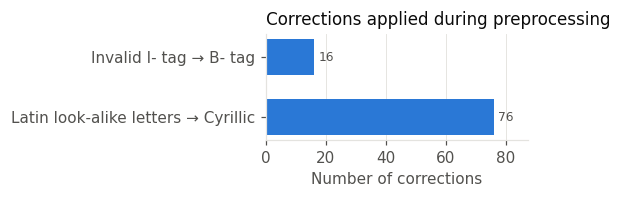

In [10]:
fig = plots.cleaning_summary(log['rule'].value_counts().rename({
    'homoglyph': 'Latin look-alike letters → Cyrillic',
    'iob2_repair': 'Invalid I- tag → B- tag',
    'unicode_nfc': 'Unicode NFC normalisation'}))
plots.save(fig, '01_cleaning_corrections', FIG)

In [11]:
kaz = load_processed(PROC, 'kaznerd')
ud  = load_processed(PROC, 'udktb')
eda.ner_quality_summary(kaz_raw, kaz)

,invalid_I_tags,conflicting_sentences
stage,,
raw,16,19
cleaned,0,19


### Разбиения до и после

,dataset,split,sentences,tokens,share_of_sentences
0,KazNERD,train,90228,1043305,0.801
1,KazNERD,dev,11167,129223,0.099
2,KazNERD,test,11307,129824,0.100
3,UD-KTB official,train,31,529,0.029
4,UD-KTB official,test,1047,10007,0.971
5,UD-KTB re-split,train,864,8320,0.801
6,UD-KTB re-split,dev,107,1106,0.099
7,UD-KTB re-split,test,107,1110,0.099


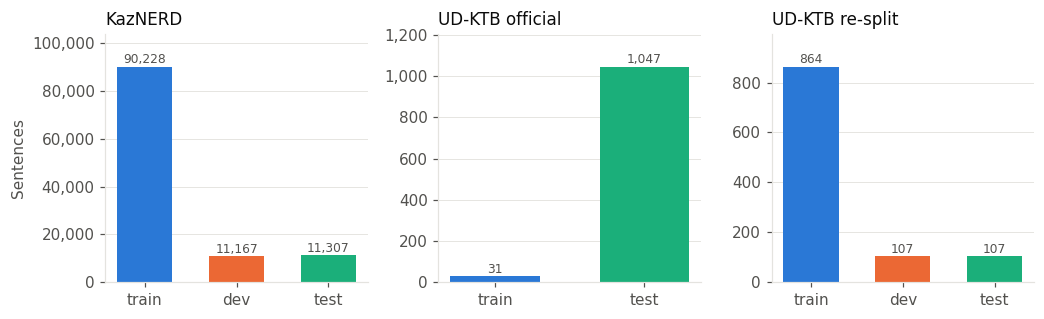

In [12]:
sizes = eda.split_sizes({'KazNERD': kaz, 'UD-KTB official': ud_raw, 'UD-KTB re-split': ud})
display(sizes)
fig = plots.split_sizes(sizes)
plots.save(fig, '02_split_sizes', FIG)

Официальный train UD-KTB не просто мал — он целиком состоит из **других** текстов, чем test.
Новый сплит повторяет жанровый состав во всех трёх частях:

,Official train,Official test,Re-split train,Re-split dev,Re-split test
akorda-random,0.000,0.304,0.294,0.299,0.299
kdt,0.000,0.275,0.266,0.271,0.271
Иран,0.000,0.135,0.131,0.131,0.131
wikipedia,0.000,0.071,0.069,0.065,0.065
story,0.000,0.047,0.045,0.047,0.047
Other,1.000,0.169,0.194,0.187,0.187


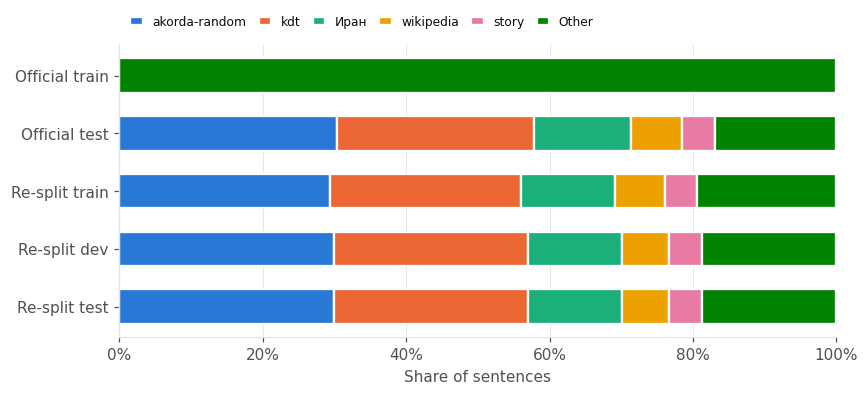

In [13]:
before, after = eda.ud_domain_mix(ud_raw), eda.ud_domain_mix(ud)
mixes = {'Official train': before['train'], 'Official test': before['test'],
         'Re-split train': after['train'], 'Re-split dev': after['dev'], 'Re-split test': after['test']}
display(pd.DataFrame(mixes))
fig = plots.domain_mix(mixes)
plots.save(fig, '03_ud_domain_mix', FIG)

## 3. Исследовательский анализ данных

Дальше всё считается на **очищенных** данных с итоговыми сплитами.

### 3.1. Распределение классов сущностей (KazNERD)

,train,dev,test
CARDINAL,23551,2886,2824
DATE,20228,2609,2611
GPE,14108,1693,1742
PERSON,10893,1352,1332
ORGANISATION,6098,759,735
POSITION,4938,601,603
MONEY,3680,441,441
PERCENTAGE,3384,443,456
ORDINAL,3105,379,386
QUANTITY,3094,407,407


,KazNERD train
classes,25
largest_class,CARDINAL
largest_share,0.215
smallest_class,NON_HUMAN
smallest_count,6
imbalance_ratio,3925.167
top3_share,0.529
classes_lt_1pct,8


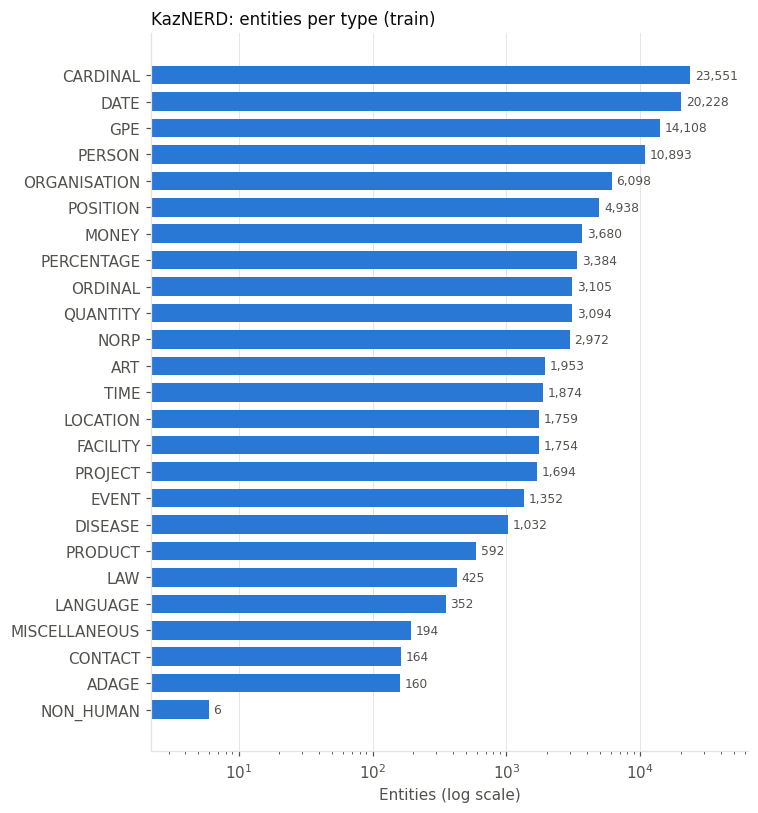

In [14]:
ner_counts = eda.ner_class_counts(kaz)
display(ner_counts)
display(eda.imbalance_summary(ner_counts['train']).to_frame('KazNERD train'))
fig = plots.class_distribution(ner_counts['train'], 'KazNERD: entities per type (train)',
                               'Entities (log scale)', log=True)
plots.save(fig, '04_ner_class_distribution', FIG)

Согласованы ли сплиты: доля каждого типа в train, dev и test.

Максимальное расхождение долей между сплитами: 0.85 п.п.


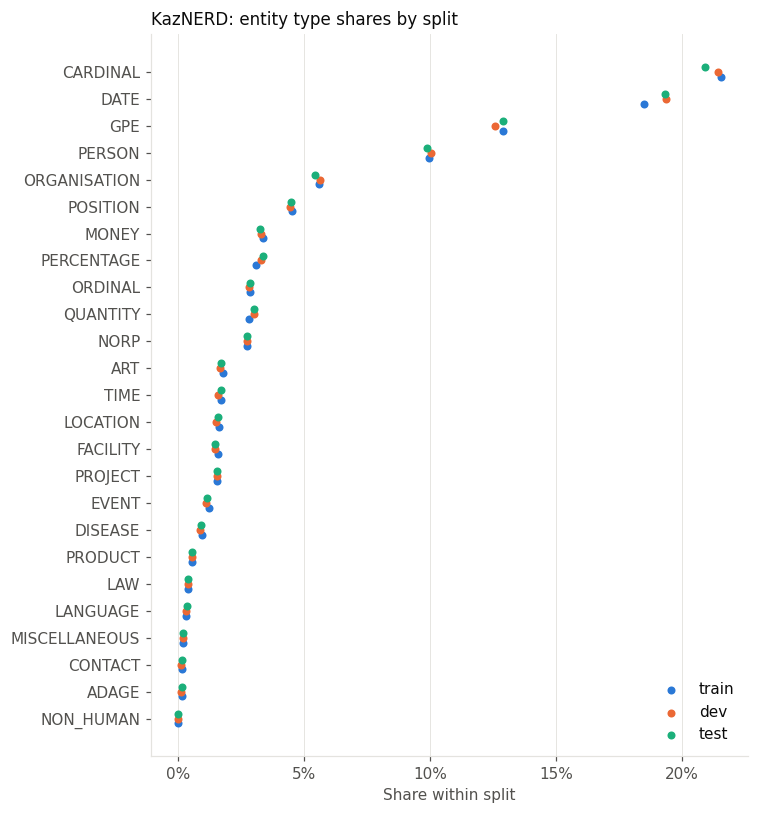

In [15]:
shares = eda.split_consistency(ner_counts)
print(f"Максимальное расхождение долей между сплитами: {shares['max_abs_diff_pp'].max():.2f} п.п.")
fig = plots.split_shares(shares, 'KazNERD: entity type shares by split')
plots.save(fig, '05_ner_split_consistency', FIG)

### 3.2. Распределение частей речи (UD-KTB)

,train,dev,test
NOUN,2438,328,334
PUNCT,1636,252,208
VERB,1299,162,182
ADJ,639,92,96
PROPN,452,61,49
PRON,392,49,52
NUM,303,30,41
AUX,298,27,36
ADV,251,21,32
DET,174,28,18


,UD-KTB train
classes,17
largest_class,NOUN
largest_share,0.293
smallest_class,SYM
smallest_count,1
imbalance_ratio,2438.000
top3_share,0.646
classes_lt_1pct,4


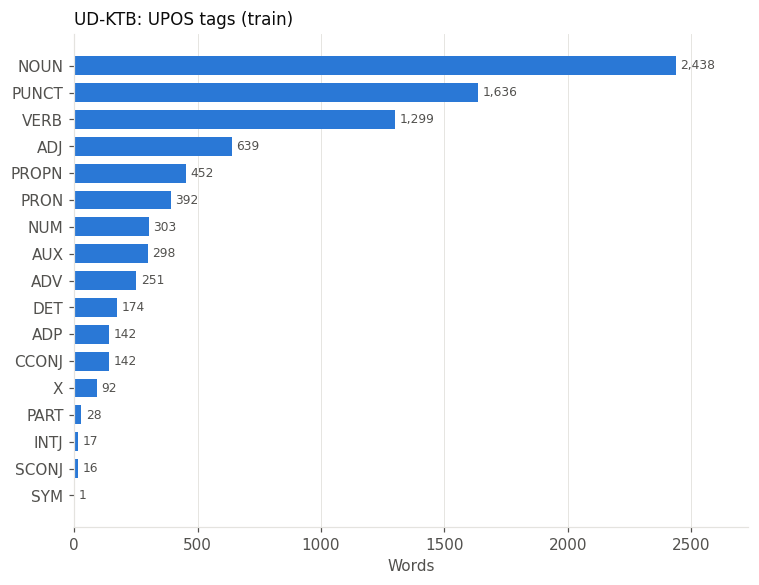

In [16]:
upos_counts = eda.token_label_counts(ud, 'upos')
display(upos_counts)
display(eda.imbalance_summary(upos_counts['train']).to_frame('UD-KTB train'))
fig = plots.class_distribution(upos_counts['train'], 'UD-KTB: UPOS tags (train)', 'Words')
plots.save(fig, '06_upos_distribution', FIG)

### 3.3. Морфологические признаки (UD-KTB)

,value
distinct_feats_strings,319.000
singletons,110.000
singletons_share,0.345
dev_unseen_feats_token_rate,0.016
test_unseen_feats_token_rate,0.016


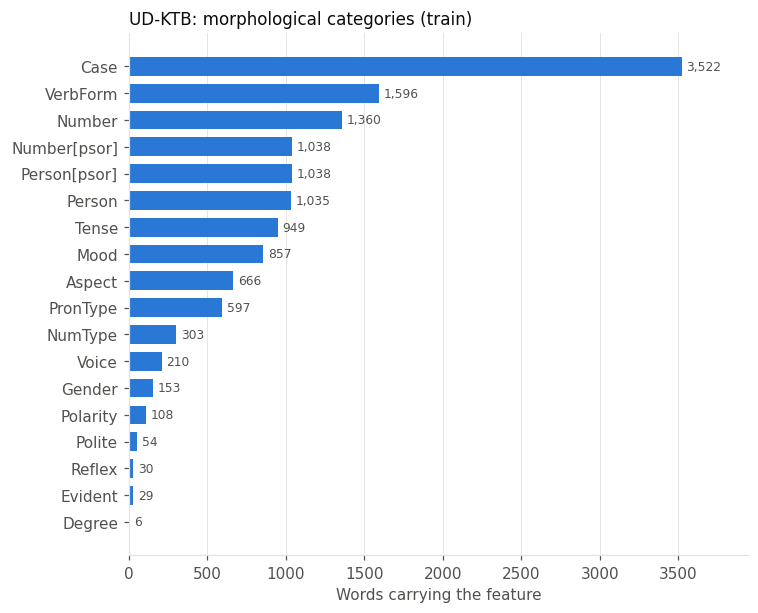

In [17]:
feats = eda.feature_counts(ud)
fig = plots.class_distribution(feats, 'UD-KTB: morphological categories (train)', 'Words carrying the feature')
plots.save(fig, '07_morph_features', FIG)
eda.feats_label_space(ud).to_frame('value')

`distinct_feats_strings` — сколько разных полных наборов признаков: это число классов, если
предсказывать FEATS целиком. Треть из них встречается в train один раз — аргумент в пользу
предсказания признаков по отдельности и в пользу правил.

### 3.4. Длина предложений и выбросы

,mean,median,min,max,upper_fence,n_long_outliers,n_short_outliers,share_outliers
dataset,,,,,,,,
KazNERD,11.556,11.000,1,71,23.000,1685,0,0.015
UD-KTB,9.774,8.000,2,51,18.500,76,0,0.071


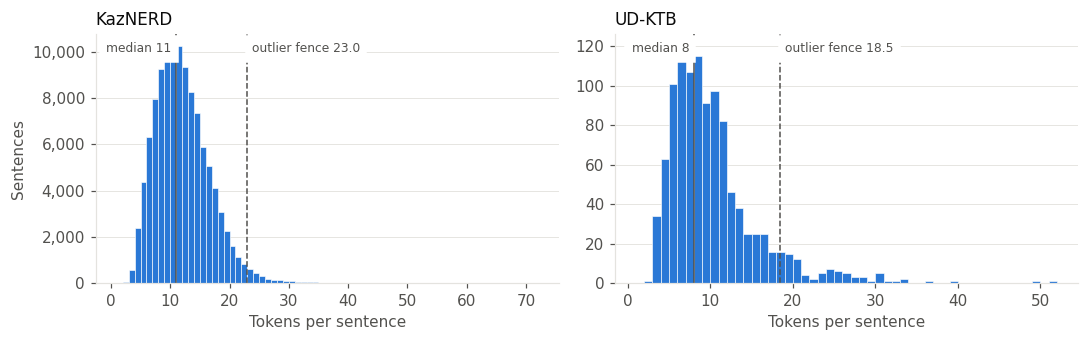

In [18]:
lengths = eda.sentence_lengths({'KazNERD': kaz, 'UD-KTB': ud})
outl = eda.length_outliers(lengths)
display(outl)
fig = plots.sentence_lengths(lengths, outl)
plots.save(fig, '08_sentence_lengths', FIG)

In [19]:
# Самые длинные предложения — посмотреть глазами, не мусор ли это
longest = sorted(kaz['train'], key=lambda s: len(s['tokens']), reverse=True)[:3]
for s in longest:
    print(len(s['tokens']), ' '.join(s['tokens'])[:250], '...\n')

71 Су тасқыны кезеңіне жеті мың үш жүз жиырма сегіз адам , бір мың алты жүз ( ыы ) отыз тоғыз техника : үш жүзі — құрал , жүз жеті — мотопомпа , жүз отыз жеті — автономды электр станциясы , жиырма тоғыз мың жеті жүз жиырма — қап , алты жүз жетпіс жеті т ...

70 Президент Тоқаевтың квазимемлекеттік секторды қысқарту туралы ұсынысын қолдай отырып , бүгін айтылған шешімін қолдай отырып , Қазақстанның бүкіл экономикасының алпыс пайыздан астамын құрайтын аталмыш сектор жұмысының ашықтығы мен есептілігін арттыру  ...

70 Президент Тоқаевтың квазимемлекеттік секторды қысқарту туралы ұсынысын қолдай отырып , бүгін айтылған шешімін қолдай отырып , Қазақстанның бүкіл экономикасының 60 пайыздан астамын құрайтын аталмыш сектор жұмысының ашықтығы мен есептілігін арттыру мақ ...



In [20]:
display(eda.token_outliers(kaz).assign(dataset='KazNERD'))
eda.token_outliers(ud).assign(dataset='UD-KTB')

,tokens,longer_than_25,with_digits,latin_only,mixed_scripts,punct_only_sentences,dataset
split,,,,,,,
train,1043305,24,27889,1280,225,1,KazNERD
dev,129223,7,3463,173,20,0,KazNERD
test,129824,4,3479,169,20,0,KazNERD


,tokens,longer_than_25,with_digits,latin_only,mixed_scripts,punct_only_sentences,dataset
split,,,,,,,
train,8320,0,193,5,0,0,UD-KTB
dev,1106,0,25,1,0,0,UD-KTB
test,1110,0,26,0,0,0,UD-KTB


### 3.5. Редкие слова и OOV

KazNERD


,types,tokens,hapax_types_share,rare_le5_types_share,oov_token_rate,oov_type_rate
split,,,,,,
train,65507,862713,0.389,0.762,0.000,0.000
dev,20503,106884,NaN,NaN,0.048,0.195
test,20650,107419,NaN,NaN,0.048,0.196


UD-KTB


,types,tokens,hapax_types_share,rare_le5_types_share,oov_token_rate,oov_type_rate
split,,,,,,
train,3636,6682,0.737,0.957,0.000,0.000
dev,700,853,NaN,NaN,0.449,0.531
test,738,901,NaN,NaN,0.413,0.497


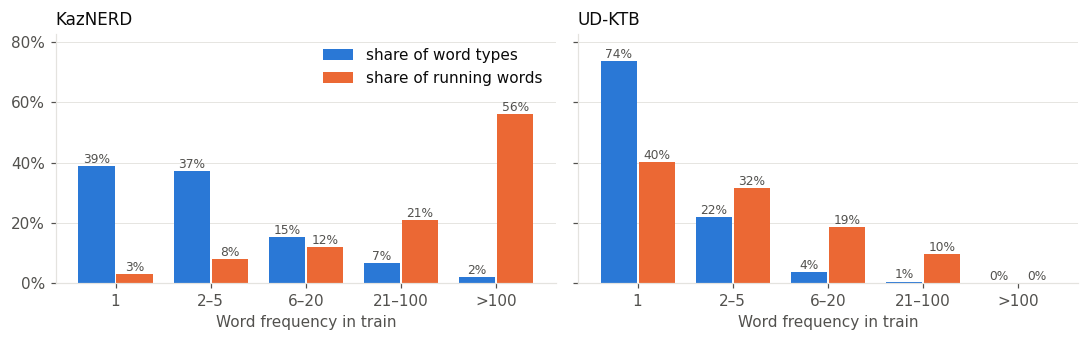

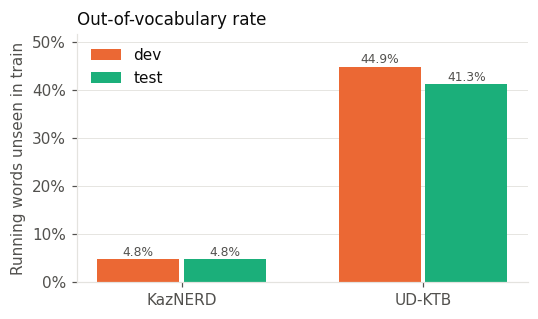

In [21]:
vocab = {'KazNERD': eda.vocabulary_stats(kaz), 'UD-KTB': eda.vocabulary_stats(ud)}
for name, v in vocab.items():
    print(name); display(v)
buckets = {'KazNERD': eda.frequency_buckets(kaz), 'UD-KTB': eda.frequency_buckets(ud)}
fig = plots.frequency_buckets(buckets)
plots.save(fig, '09_word_frequency', FIG)
fig = plots.oov_rates(vocab)
plots.save(fig, '10_oov_rate', FIG)

### 3.6. Дубликаты, утечки и пропуски в разметке

In [22]:
pd.DataFrame({ds: {'duplicates in train': q['duplicates_within']['train'],
                   'dev sentences also in train': q['leakage_from_train']['dev']['n'],
                   'test sentences also in train': q['leakage_from_train']['test']['n'],
                   'test leakage share': f"{q['leakage_from_train']['test']['share']:.1%}"}
              for ds, q in manifest['quality'].items()})

,kaznerd,udktb
duplicates in train,1374,0
dev sentences also in train,275,0
test sentences also in train,302,0
test leakage share,2.7%,0.0%


**Кандидаты в пропуски разметки NER**: одна и та же строка размечена как сущность
в одних предложениях и не размечена в других. Это кандидаты для ручной проверки,
не доказанные ошибки.

In [23]:
gaps = eda.ner_annotation_gaps(kaz)
print('Кандидатов:', len(gaps))
gaps.head(15)

Кандидатов: 81


,string,main_type,as_entity,as_O,share_unlabeled
0,Шығыс,ORGANISATION,7,41,0.854
1,Біз біргеміз,PROJECT,8,10,0.556
2,Жас кәсіпкер,PROJECT,28,8,0.222
3,алғашқы күні,DATE,5,7,0.583
4,Бір,CARDINAL,9,6,0.400
5,Ауыл,ORGANISATION,14,6,0.300
6,Өңірлерді дамыту,PROJECT,6,5,0.455
7,бұл күні,DATE,6,5,0.455
8,Халық қаһарманы,POSITION,6,4,0.400
9,Президент,POSITION,593,4,0.007


In [24]:
# UD-KTB: пустые леммы/UPOS и знаменательные слова без признаков
eda.ud_annotation_gaps(ud)

,words,missing_lemma,missing_upos,content_words_without_feats,share_content_without_feats,by_upos
split,,,,,,
train,8320,0,0,80,0.015,"{'NOUN': 79, 'AUX': 1}"
dev,1106,0,0,11,0.017,{'NOUN': 11}
test,1110,0,0,11,0.016,{'NOUN': 11}


## Выводы

1. **Масштаб.** KazNERD — 112 702 предложения (≈1,3 млн токенов), UD-KTB — 1 078 предложений
   (≈10,5 тыс. слов): разница на два порядка. Это задуманный контраст «больше ресурсов / мало ресурсов».
2. **Качество исходных данных высокое.** Ошибок формата нет; исправлено 76 латинских букв-двойников
   и 16 некорректных тегов IOB2 (только KazNERD train). Предложения не удалялись.
3. **Сплит UD-KTB пришлось пересобрать.** Официальный train — 31 предложение и целиком из других
   текстов, чем test. Новый сплит 864 / 107 / 107 стратифицирован по источнику: жанровый состав
   всех частей одинаков.
4. **Сильный дисбаланс классов.** KazNERD: CARDINAL, DATE и GPE — около половины всех сущностей,
   NON_HUMAN — 6 примеров в train (дисбаланс ≈ 3900:1), 8 типов < 1%. Поэтому кроме micro-F1
   нужно смотреть macro-F1 и F1 по классам. Доли классов в сплитах KazNERD согласованы (< 1 п.п.).
5. **Редкие слова — главная трудность UD-KTB.** 41–45% словоупотреблений dev/test не встречаются в train
   (KazNERD — ~5%). Для агглютинативного казахского это ожидаемо и прямо мотивирует
   морфологические правила в гибриде.
6. **Морфология.** 319 разных наборов FEATS, треть — единичные; почти все признаки в dev/test
   встречались в train (неизвестных наборов ~1,6%).
7. **Утечка и шум разметки KazNERD:** ~2,7% предложений test дословно есть в train, 19 предложений
   размечены противоречиво, найдены кандидаты в пропуски сущностей. Официальный сплит оставлен
   ради сравнимости; эти цифры стоит указать в главе о данных.